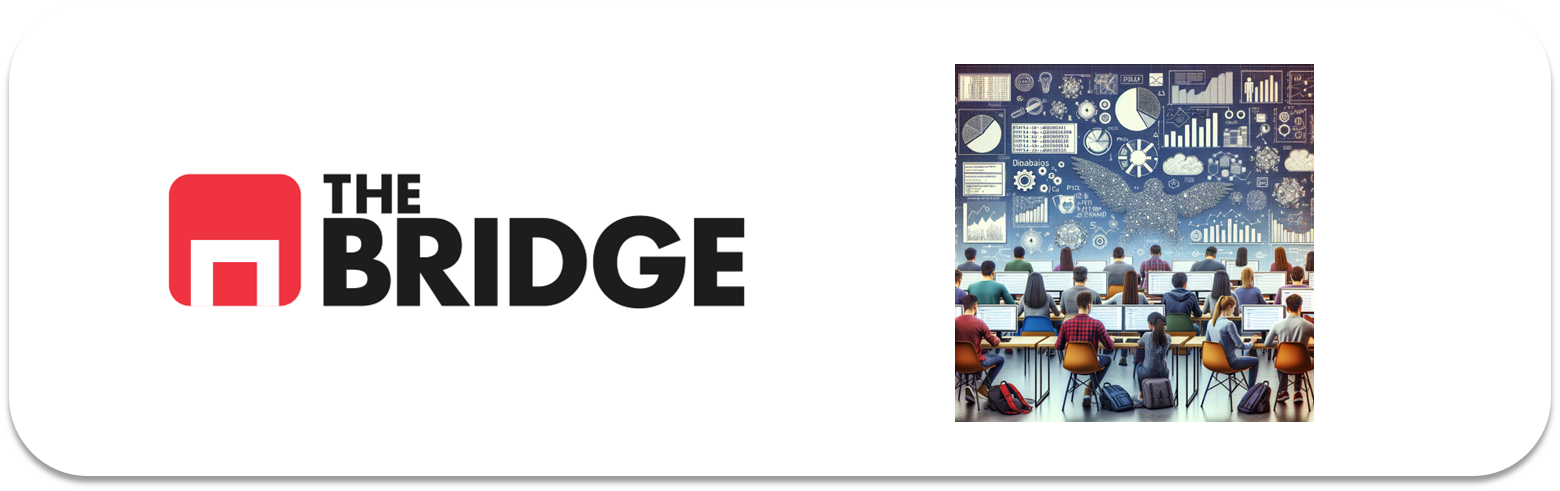

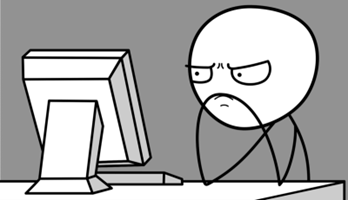

Para ejercitarte y afianzar lo aprendido sobre **Features**, completa los siguientes ejercicios. Recuerda que necesitarás datos que están en el directorio `data` (un nivel por encima, `../data`).
  
Las soluciones ya las tienes; intenta no mirarlas de primeras, pero no dejes de hacerlo cuando hayas terminado por si te pudieran aportar algo.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

### Ejercicio 1

Carga el dataset de advertising, convierte la variable edad a numérica y haz el split en train y test como hicimos en la tanda de ejercicios anterior (usa una semilla de 42 y un reparto 80-20)

In [2]:
df = pd.read_csv("../data/advertising_ml.csv")

In [3]:
df["Age"] = df["Age"].str.extract(r"(\d+)", expand=False).astype(int) 

In [4]:
train_set, test_set = train_test_split(df, test_size = 0.2, random_state = 42)

### Ejercicio 2

Aunque es algo que debemos hacer en la parte del EDA del dataset para no sobrecargar los ejercicios anteriores hemos dejado para este momento el análisis del target. Muestra las frecuencias absolutas y frecuencias relativas del target (no hace falta que hagas un gráfico)

*Frecuencias Absolutas*

In [5]:
train_set["Clicked on Ad"].value_counts()

Clicked on Ad
0    411
1    389
Name: count, dtype: int64

*Frecuencias Relativas*



In [6]:
train_set["Clicked on Ad"].value_counts(normalize = True)

Clicked on Ad
0    0.51375
1    0.48625
Name: proportion, dtype: float64

*Los valores son similares, lo cual es una suerte. Tenemos un dataset que se dice balanceado, de no haber sido similares tendríamos que haber hecho algo más como ya veremos en unidades posteriores*

### Ejercicio 3

Vamos a tratar las categóricas que se nos quedaron en el tintero: "City" y "Country" (recuerda que descartamos "Male" por su distribución de valores respecto al target que vimos en la gráfica del último ejercicio). Vuelve a calcular la cardinalidad de "City" y los valores que más se repiten:

In [7]:
train_set.City.nunique()

783

In [8]:
train_set.City.value_counts().nlargest(10)

City
Williamsport       3
New Jessicaport    2
Michelleside       2
West Amanda        2
Lake Patrick       2
North Daniel       2
Lake Susan         2
Shelbyport         2
Millertown         2
Johnstad           2
Name: count, dtype: int64

*Esta variable es muy interesante ya que tiene un porcentaje de variación muy alto (casi es única) y por lo tanto es poco informativa en el sentido de que no podemos asociar estadísticamente a ningún valor una relación destacada con la variable target, curiosamente lo mismo que nos ocurriría con una variable que tuviera un único valor...*


Independientemente de lo que hayas visto, descartamos "City" (mira la solución para una argumentación). Y nos centramos en Country.

### Ejercicio 4

Para "Country" obtén los 5 países que más se repiten y, para estos, la distribución de valores de "Clicked on Ad" 

In [9]:
train_set.Country.value_counts().nlargest(5)

Country
Afghanistan    8
Micronesia     8
Eritrea        7
Greece         7
France         7
Name: count, dtype: int64

In [10]:
top_5 = train_set.Country.value_counts().nlargest(5).index.to_list()
train_set[train_set.Country.isin(top_5)].groupby("Country")["Clicked on Ad"].value_counts(normalize= True)

Country      Clicked on Ad
Afghanistan  1                0.625000
             0                0.375000
Eritrea      0                0.571429
             1                0.428571
France       0                0.571429
             1                0.428571
Greece       0                0.571429
             1                0.428571
Micronesia   0                0.500000
             1                0.500000
Name: proportion, dtype: float64

*Dentro de lo que cabe puede que la variable sea algo discriminativa, aunque con estos países poco: en Micronesia la distribución es 50/50 y en Eritrea, Francia y Grecia casi (57/43), es decir, saber que el cliente es de uno de esos países no nos dice mucho sobre si clicará o no. Afganistán sí parece inclinarse hacia el clic (62,5%). Ojo, son muy pocos datos (7-8 clientes por país), pero el ejercicio sirve para ver cómo analizar la relación de una categórica con el target.*

### Ejercicio 5

Vamos a incluir "Country" y como es categórica debemos hacer una conversión a numérica. De los dos tipos de paso a numérica de una categórica, vamos a hacer un "One-hot encoding". Hazlo usando la función `get_dummies` de pandas. ¿Por qué crees que hacemos esta conversión?

In [11]:
train_set = pd.get_dummies(train_set, columns=["Country"])

*Mostramos las nuevas columnas: una `Country_...` por cada país presente en train (236)*

In [12]:
train_set.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Timestamp,Clicked on Ad,Country_Afghanistan,...,Country_Uruguay,Country_Uzbekistan,Country_Vanuatu,Country_Venezuela,Country_Vietnam,Country_Wallis and Futuna,Country_Western Sahara,Country_Yemen,Country_Zambia,Country_Zimbabwe
29,76.02,22,46179.97,209.82,Business-focused value-added definition,West Guybury,0,2016-01-27 12:38:16,0,False,...,False,False,False,False,False,False,False,False,False,False
535,78.76,32,70012.83,208.02,Managed attitude-oriented Internet solution,East Valerie,1,2016-04-20 10:04:29,0,False,...,True,False,False,False,False,False,False,False,False,False
695,73.49,38,67132.46,244.23,Organic 3rdgeneration encryption,Mosleyburgh,0,2016-02-14 11:36:08,0,False,...,False,False,True,False,False,False,False,False,False,False
557,79.67,28,58576.12,226.79,Total grid-enabled application,Charlesbury,0,2016-07-20 01:56:33,0,False,...,False,False,False,False,False,False,False,False,False,False
836,49.21,46,49206.40,115.60,Realigned 24/7 core,Carterland,0,2016-02-28 03:34:35,1,False,...,False,False,False,False,False,False,False,False,False,False


In [13]:
train_set.columns

Index(['Daily Time Spent on Site', 'Age', 'Area Income',
       'Daily Internet Usage', 'Ad Topic Line', 'City', 'Male', 'Timestamp',
       'Clicked on Ad', 'Country_Afghanistan',
       ...
       'Country_Uruguay', 'Country_Uzbekistan', 'Country_Vanuatu',
       'Country_Venezuela', 'Country_Vietnam', 'Country_Wallis and Futuna',
       'Country_Western Sahara', 'Country_Yemen', 'Country_Zambia',
       'Country_Zimbabwe'],
      dtype='object', length=245)

*Empleamos el one-hot encoding por el hecho de que un ordinal no tendría sentido porque son demasiados valores y el modelo interpretaría las distancias entre etiquetas como distancias reales, de forma equivocada*

*Por otro lado son demasiadas columnas, y quizás podríamos quedarnos con los países de más variación y al resto meterlo en una única etiqueta (por continente por ejemplo), pero no lo haremos en este ejercicio*

### Ejercicio 6

Ahora vamos a hacer el escalado de las features numéricas que habíamos seleccionado en los ejercicios anteriores:

["Age","Area Income","Daily Internet Usage","Daily Time Spent on Site"]

En este caso vamos a emplear la standardization (revisa la píldora y aplícala a las variables anteriores). Muestra la media y la desviación estándar del resultado.

In [14]:
features_num = ["Age","Area Income","Daily Internet Usage","Daily Time Spent on Site"]
std_scaler = StandardScaler()
train_set[features_num] = std_scaler.fit_transform(train_set[features_num])


In [15]:
train_set[features_num].describe()

,Age,Area Income,Daily Internet Usage,Daily Time Spent on Site
count,8.000000e+02,8.000000e+02,8.000000e+02,8.000000e+02
mean,1.842970e-16,-2.464695e-16,-1.243450e-16,-8.437695e-17
std,1.000626e+00,1.000626e+00,1.000626e+00,1.000626e+00
min,-1.931612e+00,-3.069950e+00,-1.746752e+00,-2.048206e+00
25%,-7.986188e-01,-5.762501e-01,-9.353360e-01,-8.821634e-01
50%,-1.188227e-01,1.450306e-01,1.259832e-01,2.257265e-01
75%,6.742728e-01,7.566823e-01,8.822010e-01,8.506335e-01
max,2.826961e+00,1.825925e+00,1.826103e+00,1.650313e+00


*Observa que la media se acerca a cero y la desviación estándar a 1 (sale 1.0006 y no 1 exacto porque `describe()` usa la desviación muestral, `ddof=1`, mientras que `StandardScaler` usa la poblacional, `ddof=0`)*

NOTA FINAL: Este dataset pide más transformaciones entre otras la de las fechas en franjas (horas, días de la semana, etc) pero lo dejamos para unidades posteriores. 